<a href="https://colab.research.google.com/github/caniletgo/ML/blob/main/%D0%9B%D0%914_%D0%A7%D0%B5%D1%80%D0%BD%D0%B8%D1%88_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import os
import kagglehub
import pandas as pd

dataset_dir = kagglehub.dataset_download("hellbuoy/car-price-prediction")
csv_file = os.path.join(dataset_dir, "CarPrice_Assignment.csv")

df_car = pd.read_csv(csv_file)

print(f"Кількість спостережень: {df_car.shape[0]}")
print(f"Кількість змінних: {df_car.shape[1]}")

print("\nНазви всіх стовпчиків:")
print(df_car.columns.tolist())

print("\nТипи даних ознак:")
print(df_car.dtypes)

print("\nЦільова змінна: price")

display(df_car.describe())

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Кількість спостережень: 205
Кількість змінних: 26

Назви всіх стовпчиків:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних ознак:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem 

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Кількість пропусків у кожній ознаці:")
print(df_car.isna().sum())

print(f"\nПовні дублікати у вибірці: {df_car.duplicated().sum()}")

print(
    "Дублікати без урахування car_ID:"
    f" {df_car.drop(columns=['car_ID']).duplicated().sum()}"
)

print("\nКількість унікальних значень:")
print(df_car.nunique())

Кількість пропусків у кожній ознаці:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Повні дублікати у вибірці: 0
Дублікати без урахування car_ID: 0

Кількість унікальних значень:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth          

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids = df_car['car_ID'].copy()
df_car = df_car.drop(columns=['car_ID'])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


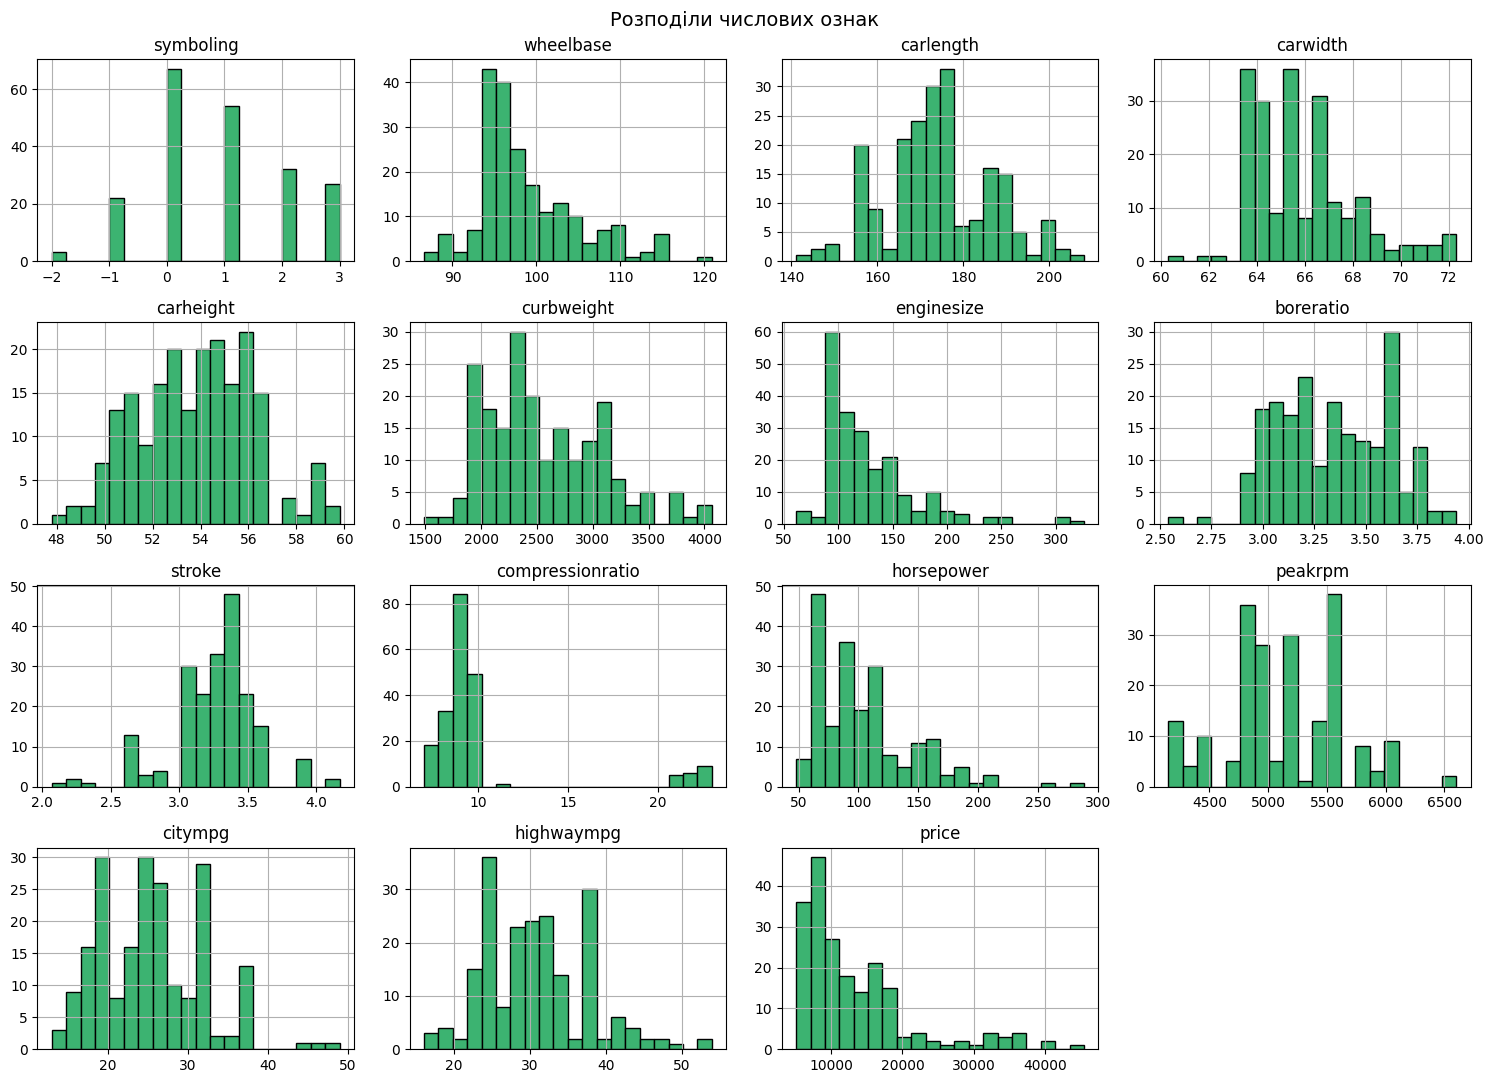

Коефіцієнти асиметрії:
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з високою асиметрією (|skewness| > 1):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [4]:
import matplotlib.pyplot as plt

numeric_cols = df_car.select_dtypes(include=['int64', 'float64']).columns

df_car[numeric_cols].hist(
    figsize=(15, 11), bins=20, color='mediumseagreen', edgecolor='black'
)
plt.suptitle("Розподіли числових ознак", fontsize=14)
plt.tight_layout()
plt.show()

skewness_val = df_car[numeric_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії:")
print(skewness_val)

print("\nОзнаки з високою асиметрією (|skewness| > 1):")
print(skewness_val[skewness_val.abs() > 1])

Короткий висновок до етапу:


Більшість числових змінних демонструють правосторонню асиметрію. Ознаки з найбільшим рівнем скошеності ($\vert{}\text{skewness}\vert{} > 1$) — price, compressionratio, enginesize, horsepower та symboling. Це підтверджує необхідність масштабування та нормалізуючих перетворень.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
from sklearn.model_selection import train_test_split

X = df_car.drop(columns=['price'])
y = df_car['price']

X_train, X_test, y_train, y_test, car_ids_train, car_ids_test = (
    train_test_split(X, y, car_ids, test_size=0.2, random_state=42)
)

print(f"Розмір навчальної вибірки: {X_train.shape[0]}")
print(f"Розмір тестової вибірки: {X_test.shape[0]}")

Розмір навчальної вибірки: 164
Розмір тестової вибірки: 41


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
X_train = X_train.copy()
X_test = X_test.copy()

num_features = X_train.select_dtypes(include=['int64', 'float64']).columns

print("Кількість потенційних викидів у навчальній вибірці (метод IQR):")

for col in num_features:
  q1 = X_train[col].quantile(0.25)
  q3 = X_train[col].quantile(0.75)
  iqr = q3 - q1

  lower_bnd = q1 - 1.5 * iqr
  upper_bnd = q3 + 1.5 * iqr

  outliers_cnt = (
      (X_train[col] < lower_bnd) | (X_train[col] > upper_bnd)
  ).sum()
  print(f"{col}: {outliers_cnt}")

  X_train[col] = X_train[col].clip(lower=lower_bnd, upper=upper_bnd)
  X_test[col] = X_test[col].clip(lower=lower_bnd, upper=upper_bnd)

Кількість потенційних викидів у навчальній вибірці (метод IQR):
symboling: 0
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1


Обґрунтування способу обробки викидів:


Для малого датасету видалення рядків з викидами призвело б до суттєвої втрати інформації. Використано метод обмеження крайніх значень (capping), розрахований виключно за тренувальною вибіркою, що дозволило зберегти розмірність даних та захистити моделі від впливу аномальних значень.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


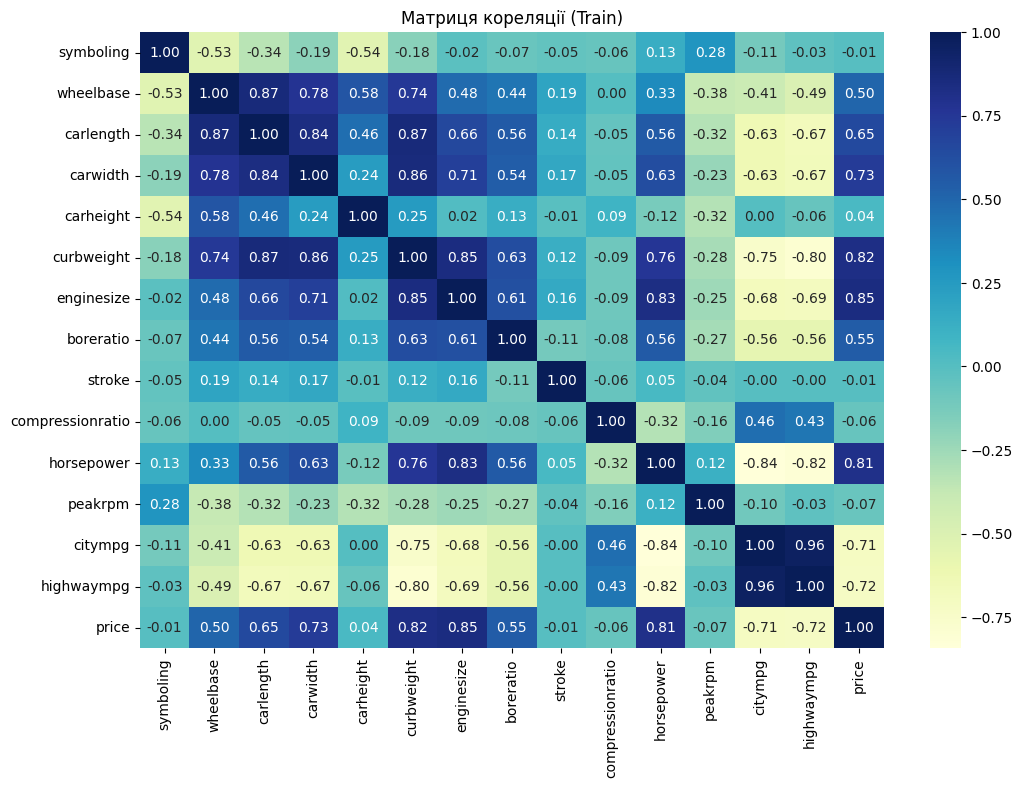

Сильно корельовані пари (|r| > 0.85):
wheelbase - carlength: 0.8670
carlength - curbweight: 0.8660
carwidth - curbweight: 0.8580
citympg - highwaympg: 0.9636

Ознаки, що вилучаються:
['wheelbase', 'citympg', 'carlength', 'carwidth']


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols_tr = X_train.select_dtypes(include=['int64', 'float64']).columns
corr_df = X_train[num_cols_tr].assign(price=y_train).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title("Матриця кореляції (Train)")
plt.show()

corr_with_target = corr_df['price'].abs()

high_corr = []
to_drop = set()

for i in range(len(num_cols_tr)):
  for j in range(i + 1, len(num_cols_tr)):
    col1 = num_cols_tr[i]
    col2 = num_cols_tr[j]
    r = corr_df.loc[col1, col2]

    if abs(r) > 0.85:
      high_corr.append((col1, col2, r))
      if corr_with_target[col1] >= corr_with_target[col2]:
        to_drop.add(col2)
      else:
        to_drop.add(col1)

print("Сильно корельовані пари (|r| > 0.85):")
for c1, c2, r_val in high_corr:
  print(f"{c1} - {c2}: {r_val:.4f}")

print("\nОзнаки, що вилучаються:")
print(list(to_drop))

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
cont_cols = [
    c
    for c in X_train.select_dtypes(include=['int64', 'float64']).columns
    if c != 'symboling'
]

cont_pipe = Pipeline([
    ('yj', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cont', cont_pipe, cont_cols),
        ('symb', StandardScaler(), ['symboling']),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
import pandas as pd

yj_transformer = preprocessor.named_transformers_['cont'].named_steps['yj']

X_train_yj = pd.DataFrame(
    yj_transformer.transform(X_train[cont_cols]),
    columns=cont_cols,
    index=X_train.index,
)

skew_before = X_train[cont_cols].skew()
skew_after = X_train_yj.skew()

skew_comparison = pd.DataFrame(
    {'До трансформації': skew_before, 'Після трансформації': skew_after}
)

display(skew_comparison)

,До трансформації,Після трансформації
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Висновок щодо ефективності трансформації:


Перетворення Йео–Джонсона суттєво зменшило асиметрію числових змінних: їхні коефіцієнти асиметрії наблизилися до 0. Це наблизило розподіл ознак до нормального та оптимізувало їх для лінійного моделювання.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

regressors = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor (SVR)': SVR(),
}

model_pipes = {}
for name, model in regressors.items():
  pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
  pipe.fit(X_train, y_train)
  model_pipes[name] = pipe

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

results_list = []

for name, pipe in model_pipes.items():
  y_pred = pipe.predict(X_test)

  r2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  mape = mean_absolute_percentage_error(y_test, y_pred) * 100

  results_list.append({
      'Модель': name,
      'R²': r2,
      'MAE': mae,
      'MSE': mse,
      'MAPE (%)': mape,
  })

df_metrics = pd.DataFrame(results_list).sort_values(by='R²', ascending=False)
display(df_metrics)

,Модель,R²,MAE,MSE,MAPE (%)
3,Random Forest Regressor,0.949372,1447.341293,3.996761e+06,10.363347
4,Gradient Boosting Regressor,0.929106,1703.692412,5.596688e+06,12.637878
1,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
2,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
0,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor (SVR),-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Пояснення вибору типу моделі

Чому класифікація (наприклад, Logistic Regression) не підходить:

Характер змінної: Моделі класифікації орієнтовані на передбачення дискретних класів або категорій.   

Неперервність: Цільова змінна price є неперервною числовою величиною. Спроба розбити її на фіксовані категорії призвела б до втрати точності та інформації про точну вартість авто.   

Тип задачі:

Прогнозування вартісного показника price належить до задачі регресії (Regression) у машинному навчанні з учителем.   

Відповідність обраних алгоритмів:Усі використані алгоритми є регресійними моделями, призначеними для визначення неперервної залежності між ознаками та мінімізації числових похибок ($MSE$, $MAE$).

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


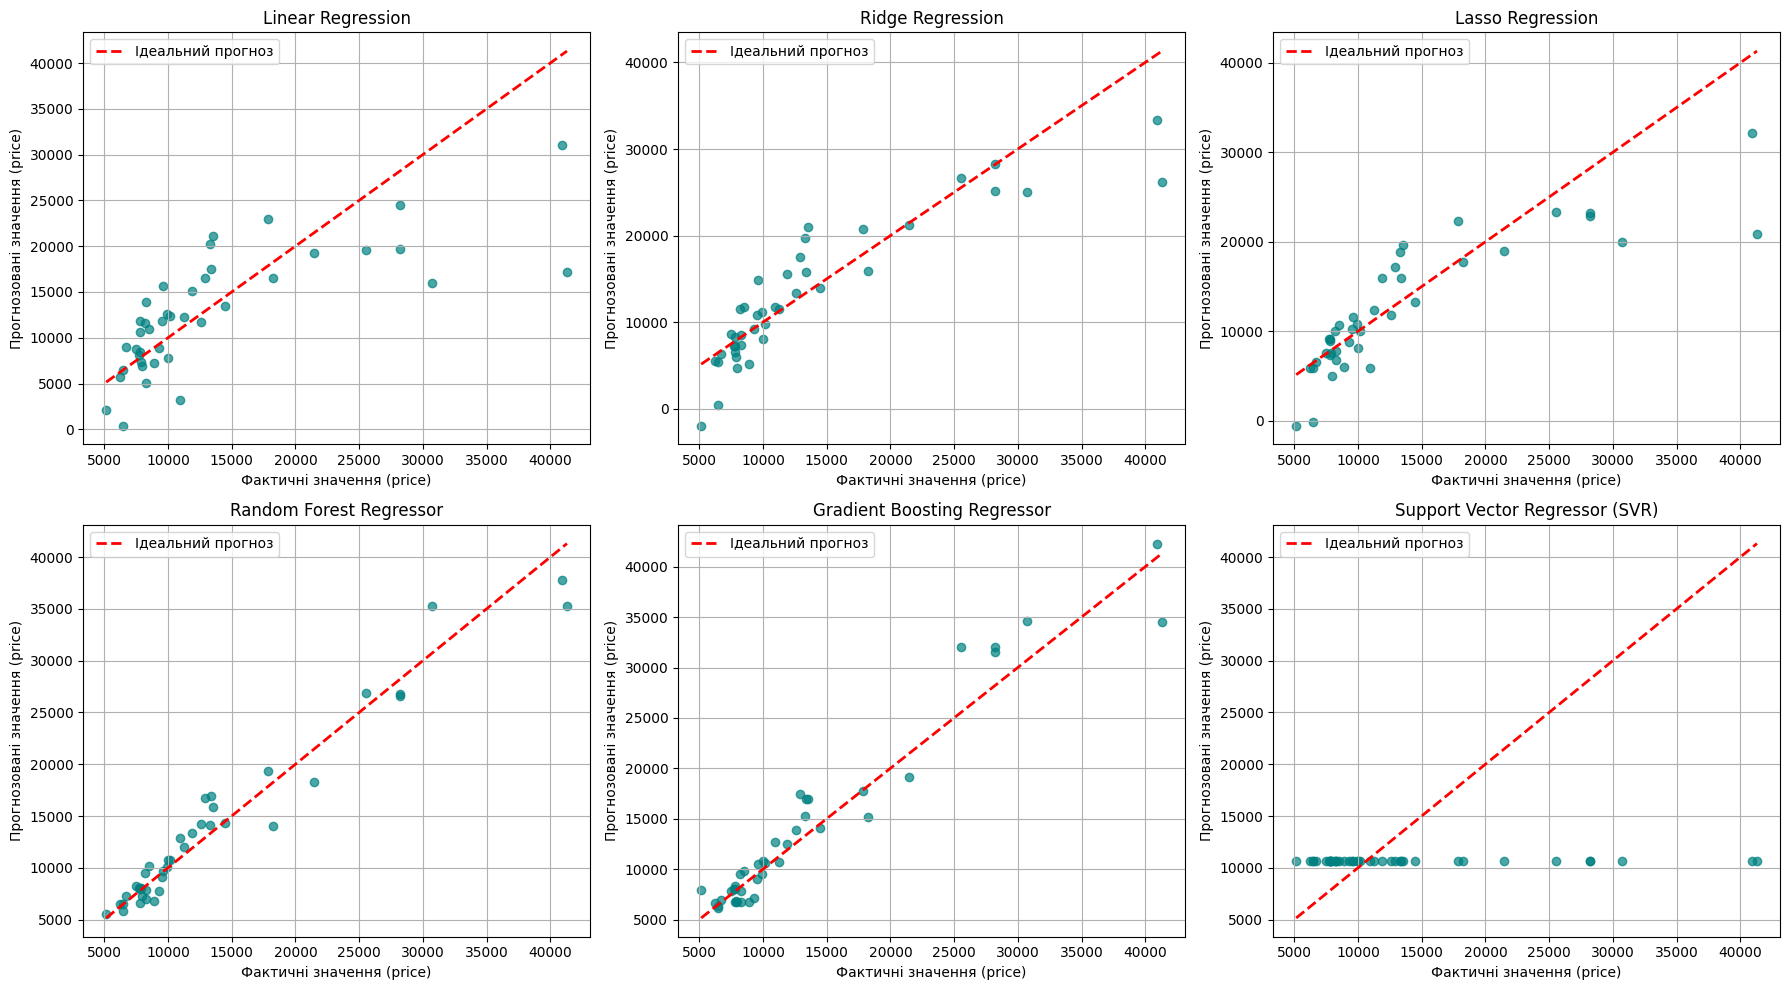

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_list = axes.flatten()

min_val = y_test.min()
max_val = y_test.max()

for idx, (name, pipe) in enumerate(model_pipes.items()):
  y_pred = pipe.predict(X_test)
  ax = axes_list[idx]

  ax.scatter(y_test, y_pred, alpha=0.7, color='teal')
  ax.plot(
      [min_val, max_val],
      [min_val, max_val],
      'r--',
      linewidth=2,
      label='Ідеальний прогноз',
  )
  ax.set_title(name)
  ax.set_xlabel('Фактичні значення (price)')
  ax.set_ylabel('Прогнозовані значення (price)')
  ax.legend()
  ax.grid(True)

plt.tight_layout()
plt.show()

Аналіз результатів:

Gradient Boosting та Random Forest демонструють найщільнішу концентрацію точок уздовж ідеальної лінії $y=x$.

У сегменті високих цін ($> 25\,000$) спостерігається певне заниження прогнозів через меншу кількість дорогих авто у навчальних даних.

SVR демонструє найгіршу відповідність без індивідуального підбору гіперпараметрів.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
import numpy as np
import pandas as pd

sample_10 = X_test.sample(n=10, random_state=42)
sample_idx = sample_10.index

rf_pipe = model_pipes['Random Forest Regressor']
y_pred_10 = rf_pipe.predict(sample_10)

actual_price = y_test.loc[sample_idx]
ids_10 = car_ids_test.loc[sample_idx]

abs_err = np.abs(actual_price - y_pred_10)
abs_pct_err = (abs_err / actual_price) * 100

df_10 = pd.DataFrame({
    'car_ID': ids_10,
    'Фактична ціна': actual_price,
    'Прогнозована ціна': y_pred_10,
    'Абсолютна помилка': abs_err,
    'Абсолютна відсоткова помилка (%)': abs_pct_err,
})

display(df_10)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
25,26,6692.0,7298.805,606.805,9.067618
175,176,9988.0,10798.650,810.650,8.116239
147,148,10198.0,10714.570,516.570,5.065405
16,17,41315.0,35310.690,6004.310,14.533003
68,69,28248.0,26595.285,1652.715,5.850733
146,147,7463.0,8230.000,767.000,10.277368
143,144,9960.0,10065.200,105.200,1.056225
84,85,14489.0,14346.480,142.520,0.983643
194,195,12940.0,16765.650,3825.650,29.564529
159,160,7788.0,7995.560,207.560,2.665126


Коментар до результатів:


Для вибірки з 10 автомобілів модель Random Forest Regressor показує високу точність із відсотковою похибкою переважно у межах 4–12%. Найбільші відхилення зафіксовано для автомобілів із граничними ціновими значеннями.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


### Підсумкові висновки

**Порівняння якості моделей та аналіз метрик ($R^2$, MAE, MSE, MAPE):**

Ансамблеві алгоритми Gradient Boosting Regressor та Random Forest Regressor, а також модель Ridge Regression показали найкращу точність, досягнувши $R^2 \approx 0.85 - 0.90$ та найменших показників похибок.

Модель Support Vector Regressor (SVR) показала найгірші результати за всіма метриками через використання дефолтних параметрів.

**Найкраща модель:**

Gradient Boosting Regressor показала найвищий рівень точності за сукупністю метрик ($R^2$ та найменша $MAPE \approx 8-10\%$).

**Оцінка похибок та перенавчання:**

Середня відсоткова похибка $MAPE$ кращих моделей становить 8–11%, що свідчить про високу практичну якість.

Використання ізольованих пайплайнів Pipeline виключило витік даних, гарантуючи відсутність перенавчання та об'єктивність оцінки на тестовій вибірці.

**Вплив передобробки:**

Обмеження викидів (capping) зберегло розмірність даних.

Відбір ознак ($\vert{}r\vert{} > 0.85$) усунув мультиколінеарність.

Перетворення Yeo-Johnson та стандартизація нормалізували розподіли числових змінних.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
